# Stage 1 | Teach ACT to pick up a centrifuge tube

**AutoBio demonstrations → ACT imitation learning → closed-loop MuJoCo testing**

This notebook answers one question: how does a robot learn tube pickup from demonstrations, and how do we check that it can actually perform the task? You do not need WorldGym, VLMs or reinforcement learning yet. Allow roughly 15–20 minutes. Follow panels **1 → 2 → 3 → 4 → 5** in the overview; the text expands them in the same order. Code cells are optional.

![Stage 1 overview: demonstrations, two ACT training conditions, closed-loop execution, measured outcomes, a local failure mechanism, joint repairs and the artifacts passed to Stage 2.](media/figures/01_system.png)

[Open the full-size overview](media/figures/01_system.png). This is a teaching illustration with archived experimental numbers. The robot drawings are not experiment screenshots.

## 1 What we built

**Start with the demonstrations in the upper-left panel, then follow the arrows toward MuJoCo.** The task is to pick up a capped centrifuge tube from a rack on an AutoBio laboratory bench. The wet-lab setting describes the task's appearance and purpose. The experiment itself takes place in **MuJoCo, a physics simulator**.

A demonstration is a recorded operation over time. It contains two camera views, the robot's joint state and the action targets issued by the demonstrator. The public data used here contains **100 trajectories, 49,959 frames, sampled at 50 Hz**. We assigned 80 trajectories to the training pool, 10 to validation and checkpoint selection, and held out another 10. The `10-demo` condition uses a fixed subset of those 80 training trajectories; `80-demo` uses the full training pool. These names describe **training data quantity**, not network depth or test count.

**ACT is the policy that learns.** A policy maps the current observation to an action. Here, supervised imitation learning trains ACT to predict the actions recorded in the demonstrations. A saved set of model parameters is a **checkpoint**. Different demonstration counts, training settings or checkpoints can produce policies with different behavior.

Now look at the center of the diagram. One decision uses front RGB, wrist RGB and a seven-dimensional robot state: six arm joints plus the gripper state. ACT extracts visual features with ResNet-18 and combines them with the state through a Transformer. It predicts a **50×7 action chunk**: seven joint/gripper targets for each of the next 50 control steps. These are joint targets, not instructions such as “move the gripper three centimeters to the left.”

The following real input was saved in a **later ACT40 demonstration of the same task**. It illustrates the two camera views and array shapes; it is not the source of the 50-scene results in the next section.

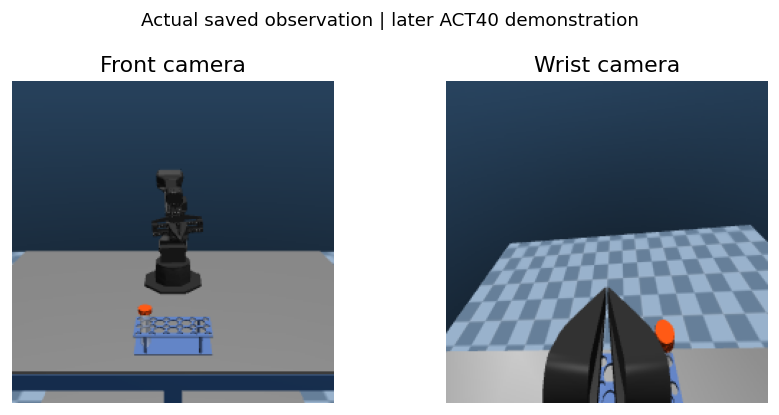

Joint-state shape: (7,)
Action-chunk shape: (50, 7)


In [1]:
from briefing_utils import *
verify_assets()
input_views()

**Follow the arrow into MuJoCo, then around the feedback loop.** MuJoCo executes the targets, moving the robot and tube. The repaired runner consumes all 50 actions in order. At 50 Hz, this takes about one second. It then reads fresh images and state and predicts the next chunk. There is no replanning inside a chunk, but observations feed back between chunks, so the overall execution is closed-loop.

For example, the first observation may show the gripper above the rack, prompting an approach. A later observation shows it near the cap, allowing subsequent actions to close the gripper and lift. No person tells ACT “close now” during the test: the control targets come from the policy.

Success is checked using the official task rule, not a visual impression. At a checked instant, **the tube body must be above 0.925 m in world coordinates, and the left finger must contact the cap**. This records whether the success condition was reached; it does not guarantee an indefinitely stable grasp. The policy does not receive the tube's true position as an action shortcut.

> **Checkpoint for understanding:** ACT learns observation-to-action behavior. MuJoCo executes the actions and supplies the next observation. WorldGym has not been used to train ACT in this stage.

## 2 What actually happened

**Read the result table only after separating training from testing.** A demonstration is a recording used for learning. A test seed specifies a randomized initial state for a new trial. Fifty test seeds mean 50 initial states of the same pickup task, not 50 different tasks.

| Version | 10-demo ACT | 80-demo ACT |
|---|---:|---:|
| Original, both trained for 20k steps | 0/50 | 0/50 |
| Matched repair, both trained to 44k cumulative steps | **31/50 (62%)** | **50/50 (100%)** |

The two repaired policies used the same 50 new test initial states, with matched architecture, training budget, sampling and execution rules. Both training runs reached 44k steps. Validation selected the 44k checkpoint for 10-demo and the 43k checkpoint for 80-demo. Final test outcomes were not used to select these checkpoints.

The original and repaired versions used **different test initial states**, and several aspects of training and execution changed together. The table shows that the original failed and the combined repair produced usable policies. It does **not** identify how much each repair contributed. The paired 10-demo versus 80-demo test does compare demonstration quantities within the repaired setup.

The next cell recounts the saved binary outcomes for the repaired policies. It does not rerun the robot.

In [2]:
phase1_results()
check_stage_evidence()

Repaired policy,Successes,Paired scenes,Observed success rate
10-demo ACT,31,50,62.0%
80-demo ACT,50,50,100.0%


{'phase1_paired_scenes': 50,
 'phase2_paired_scenes': 20,
 'status': 'PASS_SAVED_OUTCOME_ARITHMETIC',
 'new_inference': False}

50/50 means success in all 50 observed trials, not guaranteed success in every possible initial state. The Wilson 95% interval is approximately 92.9%–100%; for 31/50 it is 48.2%–74.1%. These intervals describe finite-test uncertainty. They do not include the variation that another independent training seed might produce.

## 3 Why the first version stalled

**Look at “approach → close → lift.”** One predicted chunk can contain a useful sequence of behavior. If the runner predicts 50 actions, executes only the first 10 and then immediately replans, the closing or lifting actions later in the chunk may repeatedly be discarded. The policy keeps generating actions while the operation appears stuck.

A local comparison used the **same frozen 40k ACT and the same three development scenes**. Executing 10 actions before replanning gave 0/3 successes; consuming all 50 gave 3/3. This supports premature replanning as a local failure mechanism. It does not prove that this mechanism explains every failure, and 3/3 is not the formal 50-scene result.

An implementation detail matters here: **handing 10 actions at a time to an evaluator is not the same as calling ACT again every 10 actions**. The repaired runner stores all 50 predictions in a queue. The evaluator takes five packets of 10 before a new prediction is needed. Later strong ACT experiments also use this 50-action queue. Seeing the number 10 in evaluator code is not evidence that they retain the original problem.

> Think of a 50-line operating checklist. Collecting ten lines at a time until all fifty are executed differs from throwing away the remaining forty lines and writing a new checklist after every ten.

## 4 What the repair changed

**The four repairs in the image correspond to four concrete operations.** Together they define the repaired version; they are not four separately established causal findings.

| Change | Why it was made | What was established |
|---|---|---|
| Align next-action supervision with target offset +1 | The action to execute after the current image must match its training label | Used in the repair; its individual success-rate contribution was not isolated |
| Sample more around gripper closure | A short, decisive transition can be underrepresented by uniform trajectory sampling | Roughly half the samples came from a closure window, half from uniform sampling |
| Consume the full 50-action chunk | Preserve the predicted sequence instead of repeatedly dropping its later actions | The same-policy, three-scene comparison supports this local mechanism |
| Match both runs at 44k cumulative training steps | Give the two demonstration-count conditions the same training budget | Checkpoints and execution rules were fixed before final testing |

Why can low training error coexist with failed pickup? During training, ACT sees observations from expert demonstrations. During testing, it sees the consequences of **its own** actions. A small early deviation changes later images. **Action prediction error is the training signal; completed pickup is the closed-loop task metric.** This is why we must actually run the policy in MuJoCo.

## 5 What Stage 2 receives

Stage 1 leaves three useful artifacts: **frozen ACT weights, official success labels for each seed, and MuJoCo videos with control/state traces**. They make the next question testable: if a world model supplies future observations instead of physical dynamics, can it identify which ACT policy is better?

Stage 2 therefore keeps ACT weights fixed and changes the environment producing future observations. Its scores are checked against independent MuJoCo outcomes. Moving from training to evaluation changes the research question; it is not a new name for the same training process.

**Where is the executable code?** The [ACT SFT entry](Scripts/sft_act.py), [evaluation entry](Scripts/evaluate.py) and [reproduction guide](Scripts/README.md) support later checkpoint-based ACT continuation and testing. The compact ACT entry starts from an existing 10-demo checkpoint. It is not a one-command rerun of the entire historical 10/80-demo rescue. This CPU notebook verifies saved results; GPU execution additionally requires the unpublished task-asset bundle.

**A precise research summary:** “I established closed-loop ACT baselines for an AutoBio simulation task, aligned training and execution, and compared matched 10/80-demonstration conditions to create frozen policies and physical-simulation references for world-model evaluation.”

Before continuing, explain without jargon: what does ACT observe, what does it output, who decides success, and why does 50/50 not establish real-robot reliability?

[Continue to Stage 2: evaluate fixed policies](02_worldgym_policy_evaluation.ipynb)

<details><summary>Evidence and verification scope</summary>

[Stage 1 summary](evidence/phase1_summary.json) records source filenames and SHA256 hashes. [Per-scene repaired outcomes](evidence/phase1_outcomes.csv) contains all 100 trials. Original 0/50 and local 0/3 versus 3/3 numbers come from the archived report and were not rerun for this lesson. The input example is from a later ACT40 demonstration. No new training or real-robot experiment was performed.

</details>